<a href="https://colab.research.google.com/github/there-are-places/Mnist_dataset/blob/main/mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
import numpy as np
from io import BytesIO
import random
import requests
from matplotlib import pyplot as pyp
import cv2
from google.colab.patches import cv2_imshow

r=requests.get('https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz',stream=True)
data=np.load(BytesIO(r.raw.read()))

X_train=data['x_train']
Y_train=data['y_train']
X_test=data['x_test']
Y_test=data['y_test']


print('X train:'+str(X_train.shape))
print('Y train:'+str(Y_train.shape))
print('X test:'+str(X_test.shape))
print('Y test:'+str(Y_test.shape))

print(data['x_train'])


X train:(60000, 28, 28)
Y train:(60000,)
X test:(10000, 28, 28)
Y test:(10000,)
[[[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 ...

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]]


In [50]:
print(data)

NpzFile 'object' with keys: x_test, x_train, y_train, y_test


**Dataset**

In [51]:
X_train=data['x_train']
type(X_train)

numpy.ndarray

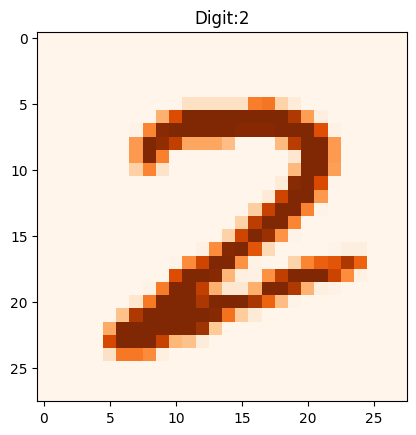

In [52]:
a=random.randint(0,10000)
pyp.imshow(X_train[a],cmap='Oranges')
pyp.title(f"Digit:{Y_train[a]}")
pyp.show()

In [53]:
X_train.max()

np.uint8(255)

**Resized_image**

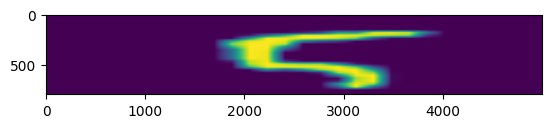

In [54]:
img = X_train[100]
resized_image = cv2.resize(img, (5000, 800))
resized_image_rgb = cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGBA)
pyp.imshow(resized_image)
pyp.show()

**Gaussian Blur**

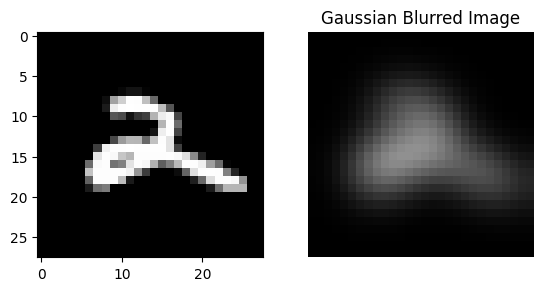

In [55]:
X_train=data['x_train']
img=X_train[4687]

pyp.subplot(1,2,1)
pyp.imshow(img,cmap='gray')
Gaussian = cv2.GaussianBlur(img, (15, 15), 0)
Gaussian_rgb = cv2.cvtColor(Gaussian, cv2.COLOR_BGR2RGB)
pyp.subplot(1,2,2)
pyp.imshow(Gaussian_rgb)
pyp.title('Gaussian Blurred Image')
pyp.axis('off')
pyp.show()

**Sharpening**

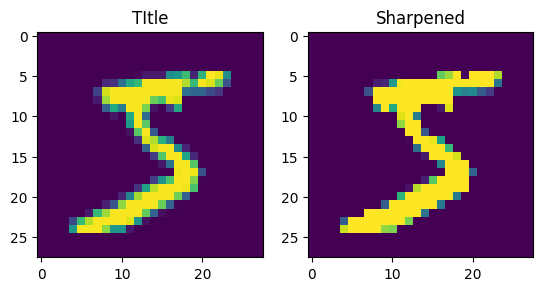

In [56]:
import cv2

img=X_train[0]
sharp_img=cv2.addWeighted(img,2,cv2.GaussianBlur(img,(0,0),5),-1,0)


pyp.subplot(1,2,1)
pyp.imshow(img)
pyp.title("TItle")
pyp.subplot(1,2,2)
pyp.imshow(sharp_img)
pyp.title("Sharpened")
pyp.show()

**Normalization**

In [76]:
img=X_train[47]
print(img)
print(img.min,img.max)

norm=cv2.normalize(img,None,0,1.0,cv2.NORM_MINMAX,dtype=cv2.CV_32F)

cv2_imshow(norm)

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
  128 128 255 255 255 255 255  64   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 128 255
  255 255 255 255 255 255 255 255   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  6

**Edge Detection**

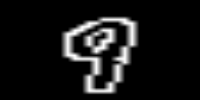

In [72]:
  from google.colab.patches import cv2_imshow
img=X_train[900]

blur=cv2.GaussianBlur(img,(5,5),1.4)

edges=cv2.Canny(blur,threshold1=100,threshold2=200)
resized_image=cv2.resize(edges,(200,100))
cv2_imshow(resized_image)
